# EuroSAT MS — Data Exploration

Sanity-check the dataset before training:
- file structure, class counts
- per-tile shape, dtype, value range
- what each of the 13 spectral bands looks like
- RGB vs. false-color (NIR) renderings
- per-class spectral signatures
- NDVI (vegetation index)
- per-channel mean/std for normalization

In [1]:
%load_ext autoreload
%autoreload 2

from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import rasterio

from lib.constants import BANDS, CLASSES, NUM_BANDS, PATH_TO_DATASET, RGB_BAND_INDICES
from lib.dataset import discover_samples

## 1. Dataset overview

In [2]:
samples = discover_samples()
counts = Counter(label for _, label in samples)

print(f"Total tiles: {len(samples)}")
print(f"Path:        {PATH_TO_DATASET}")
print()
for idx, name in enumerate(CLASSES):
    print(f"  {name:<22} {counts[idx]:>5}")

Total tiles: 27000
Path:        data/eurosat/EuroSAT_MS

  AnnualCrop              3000
  Forest                  3000
  HerbaceousVegetation    3000
  Highway                 2500
  Industrial              2500
  Pasture                 2000
  PermanentCrop           2500
  Residential             3000
  River                   2500
  SeaLake                 3000


## 2. Inspect a single tile

In [3]:
sample_path, sample_label = samples[0]
with rasterio.open(sample_path) as src:
    tile = src.read()  # (bands, H, W)
    profile = src.profile

print(f"path:   {sample_path.name}")
print(f"class:  {CLASSES[sample_label]}")
print(f"shape:  {tile.shape}")
print(f"dtype:  {tile.dtype}")
print(f"min:    {tile.min()}")
print(f"max:    {tile.max()}")
print(f"crs:    {profile.get('crs')}")
print(f"transform pixel size: {profile['transform'].a:.2f} m")

path:   AnnualCrop_1.tif
class:  AnnualCrop
shape:  (13, 64, 64)
dtype:  uint16
min:    9
max:    3490
crs:    EPSG:32635
transform pixel size: 10.01 m


## 3. All 13 bands of one tile

Each band is shown with its own min/max stretch so structure is visible. Notice how NIR (B08) and SWIR (B11/B12) reveal information that RGB misses.

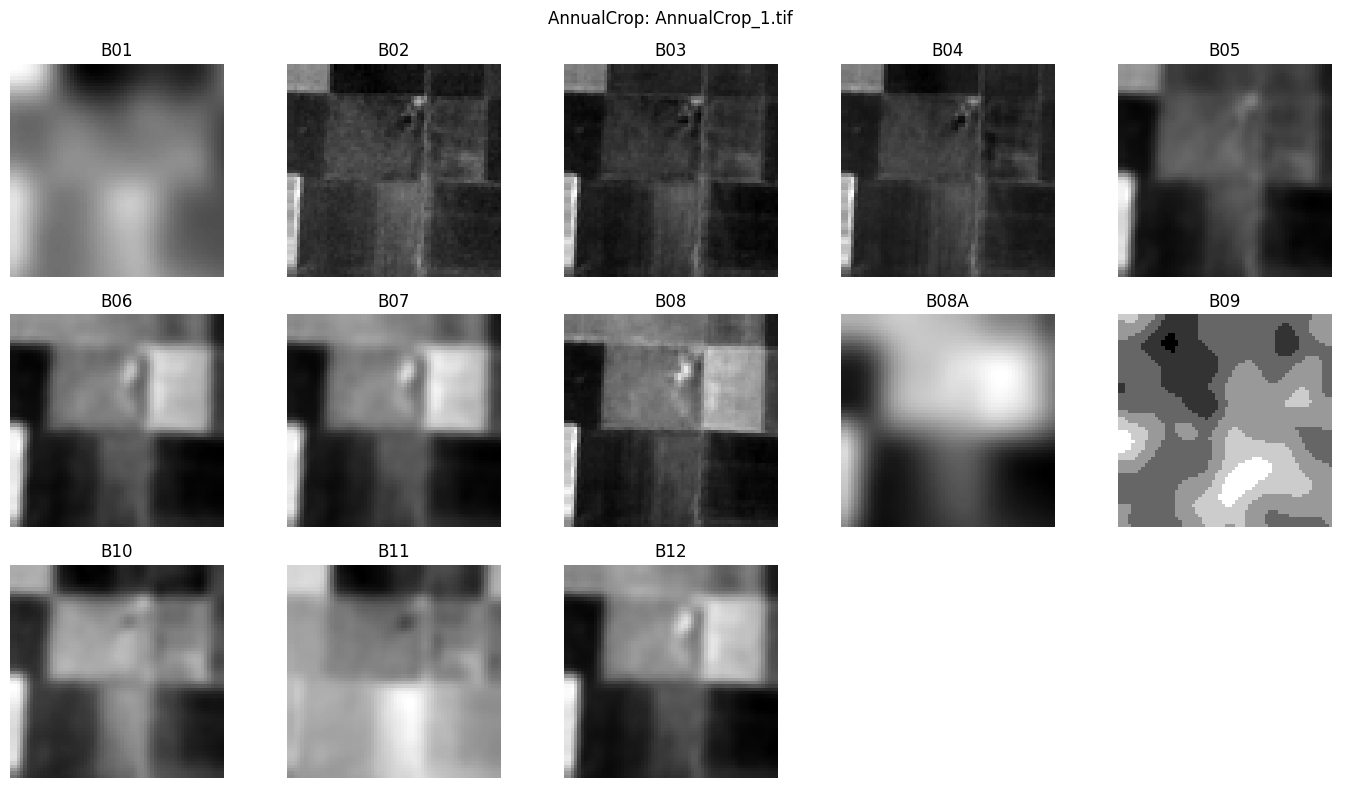

In [4]:
def plot_all_bands(tile, title=""):
    fig, axes = plt.subplots(3, 5, figsize=(14, 8))
    for i, ax in enumerate(axes.flat):
        if i < NUM_BANDS:
            ax.imshow(tile[i], cmap="gray")
            ax.set_title(BANDS[i])
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_all_bands(tile, title=f"{CLASSES[sample_label]}: {sample_path.name}")

## 4. RGB vs. false-color renderings

- **True color**: B04 / B03 / B02 — what the eye would see
- **False color (NIR)**: B08 / B04 / B03 — vegetation appears red, very useful for land cover

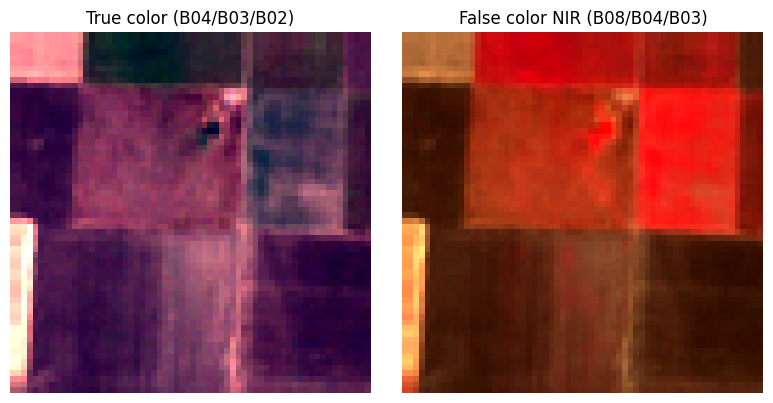

In [5]:
def stretch(arr, p_low=2, p_high=98):
    """Percentile stretch for visualisation only (does not affect ML pipeline)."""
    lo, hi = np.percentile(arr, (p_low, p_high))
    return np.clip((arr - lo) / (hi - lo + 1e-6), 0, 1)


def true_color(tile):
    rgb = tile[list(RGB_BAND_INDICES)].astype(np.float32)
    return stretch(rgb).transpose(1, 2, 0)


def false_color_nir(tile):
    # R = NIR (B08, idx 7), G = Red (B04, idx 3), B = Green (B03, idx 2)
    fc = tile[[7, 3, 2]].astype(np.float32)
    return stretch(fc).transpose(1, 2, 0)


fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(true_color(tile))
axes[0].set_title("True color (B04/B03/B02)")
axes[1].imshow(false_color_nir(tile))
axes[1].set_title("False color NIR (B08/B04/B03)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. One tile per class — true color and false-color side by side

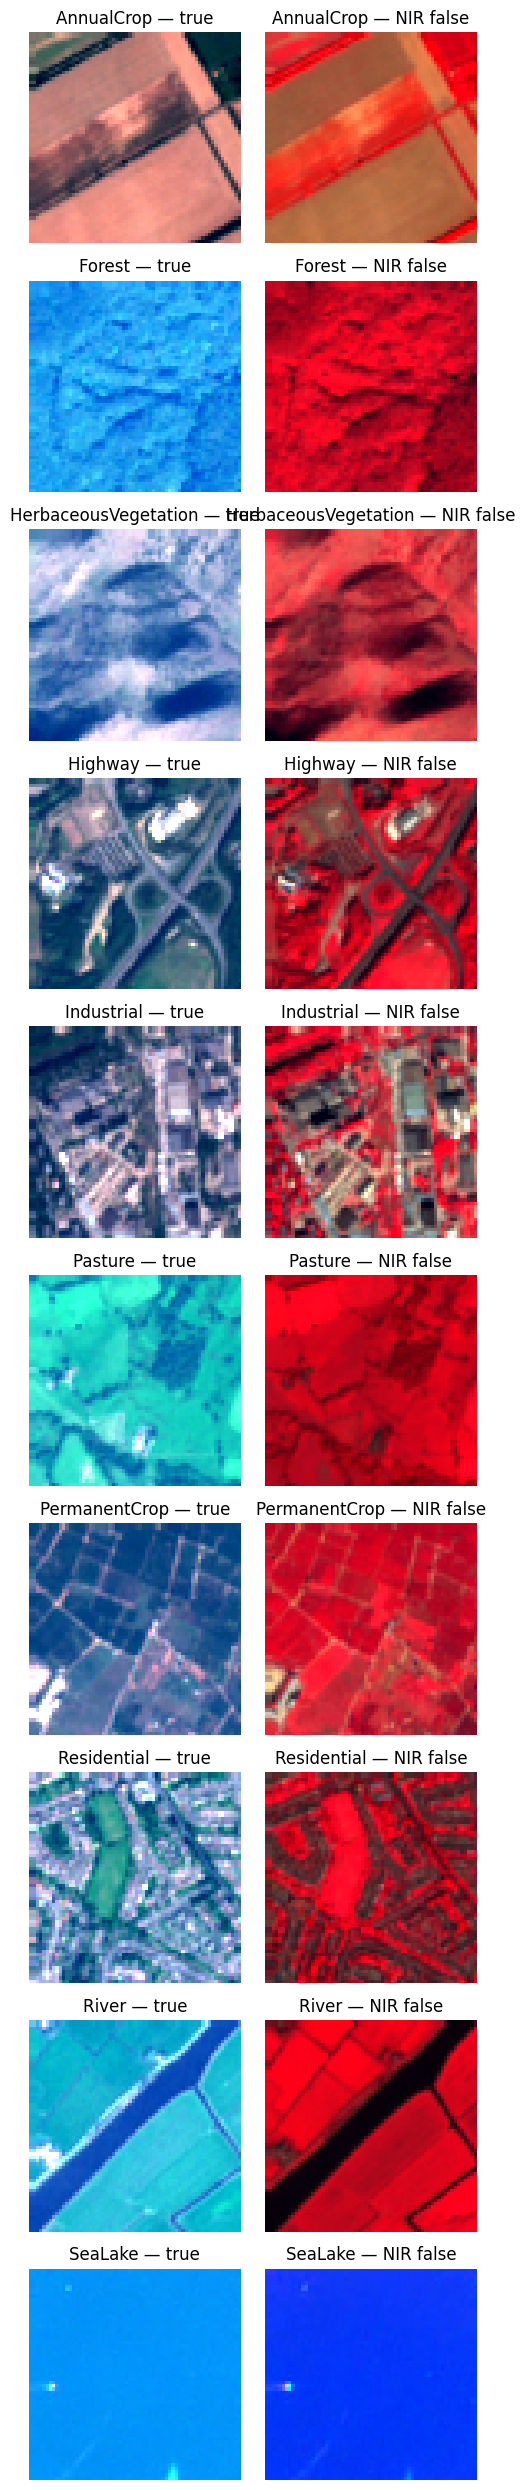

In [6]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(CLASSES), 2, figsize=(5, 2.5 * len(CLASSES)))
for row, class_name in enumerate(CLASSES):
    class_samples = [s for s in samples if s[1] == CLASSES.index(class_name)]
    path, _ = class_samples[rng.integers(len(class_samples))]
    with rasterio.open(path) as src:
        t = src.read()
    axes[row, 0].imshow(true_color(t))
    axes[row, 0].set_title(f"{class_name} — true")
    axes[row, 1].imshow(false_color_nir(t))
    axes[row, 1].set_title(f"{class_name} — NIR false")
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Per-class spectral signature

Mean reflectance across each band, averaged over a few tiles per class. Classes that are visually similar in RGB (e.g. AnnualCrop vs. PermanentCrop) often separate cleanly in NIR / SWIR — that's the leverage the from-scratch 13-channel CNN should be able to exploit.

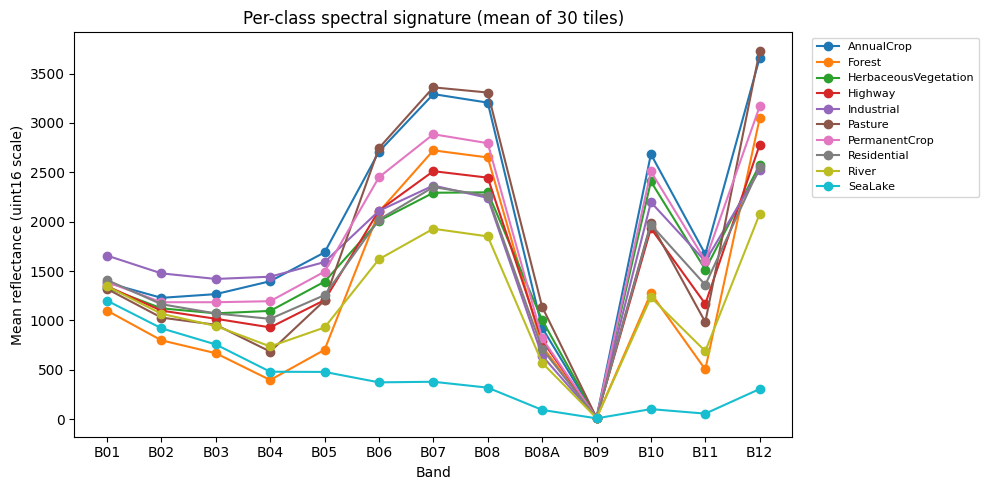

In [7]:
N_PER_CLASS = 30
rng = np.random.default_rng(0)

mean_per_class = np.zeros((len(CLASSES), NUM_BANDS))
for idx, class_name in enumerate(CLASSES):
    class_samples = [s for s in samples if s[1] == idx]
    chosen = rng.choice(len(class_samples), size=N_PER_CLASS, replace=False)
    accum = np.zeros(NUM_BANDS)
    for k in chosen:
        path, _ = class_samples[k]
        with rasterio.open(path) as src:
            t = src.read().astype(np.float32)
        accum += t.reshape(NUM_BANDS, -1).mean(axis=1)
    mean_per_class[idx] = accum / N_PER_CLASS

fig, ax = plt.subplots(figsize=(10, 5))
for idx, class_name in enumerate(CLASSES):
    ax.plot(BANDS, mean_per_class[idx], marker="o", label=class_name)
ax.set_xlabel("Band")
ax.set_ylabel("Mean reflectance (uint16 scale)")
ax.set_title(f"Per-class spectral signature (mean of {N_PER_CLASS} tiles)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 7. NDVI map

NDVI = (NIR − Red) / (NIR + Red). High = vegetation, low = water / built-up.

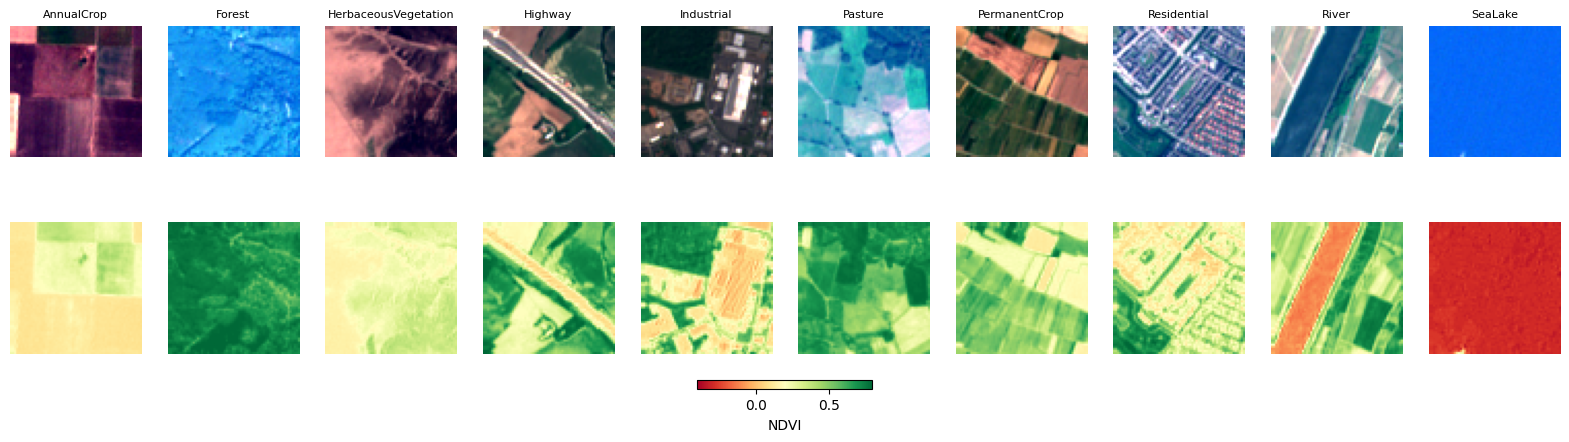

In [8]:
def ndvi(tile):
    nir = tile[7].astype(np.float32)   # B08
    red = tile[3].astype(np.float32)   # B04
    return (nir - red) / (nir + red + 1e-6)


fig, axes = plt.subplots(2, len(CLASSES), figsize=(2 * len(CLASSES), 5))
for col, class_name in enumerate(CLASSES):
    class_samples = [s for s in samples if s[1] == CLASSES.index(class_name)]
    path, _ = class_samples[0]
    with rasterio.open(path) as src:
        t = src.read()
    axes[0, col].imshow(true_color(t))
    axes[0, col].set_title(class_name, fontsize=8)
    axes[0, col].axis("off")
    im = axes[1, col].imshow(ndvi(t), cmap="RdYlGn", vmin=-0.4, vmax=0.8)
    axes[1, col].axis("off")
fig.colorbar(im, ax=axes[1, :], orientation="horizontal", fraction=0.05, label="NDVI")
plt.show()

## 8. Per-channel mean and std (sample-based)

Quick estimate from a random 500-tile sample. The **real** normalization stats for training must be computed on the **train split only** — this cell is just for getting a feel for the magnitudes.

In [9]:
SAMPLE_SIZE = 500
rng = np.random.default_rng(42)
chosen = rng.choice(len(samples), size=SAMPLE_SIZE, replace=False)

stack = np.zeros((SAMPLE_SIZE, NUM_BANDS, 64, 64), dtype=np.float32)
for i, k in enumerate(chosen):
    path, _ = samples[k]
    with rasterio.open(path) as src:
        stack[i] = src.read()

mean = stack.mean(axis=(0, 2, 3))
std = stack.std(axis=(0, 2, 3))

print(f"{'band':<6} {'mean':>10} {'std':>10}")
for name, m, s in zip(BANDS, mean, std):
    print(f"{name:<6} {m:>10.1f} {s:>10.1f}")

band         mean        std
B01        1361.0      255.5
B02        1125.4      345.7
B03        1048.3      406.6
B04         960.4      600.2
B05        1207.0      569.5
B06        2008.1      848.1
B07        2376.7     1071.1
B08        2300.5     1101.5
B08A        731.6      401.6
B09          12.3        4.9
B10        1844.7      991.3
B11        1147.0      760.2
B12        2599.2     1207.4
